Task 2.4

In [20]:
import time
import numpy as np
import matplotlib.pyplot as plt
import k3d

In [21]:
# 1) Детектор и поиск ФЭУ
class Detector:
    def __init__(self, R=15.0, N=2000, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a
        self.fmt_positions = self.generate_fmts()
        self.z_coords = self.fmt_positions[:, 2]

    def generate_fmts(self):
        i = np.arange(self.N)
        z = -self.R + 2 * self.R * (i + 0.5) / self.N
        r_xy = np.sqrt(self.R**2 - z**2)
        phi = i * np.pi / np.e

        x = r_xy * np.cos(phi)
        y = r_xy * np.sin(phi)
        return np.column_stack([x, y, z])

    def find_fmt_fast(self, point):
        z = point[2]
        i0 = np.searchsorted(self.z_coords, z - self.r)
        i1 = np.searchsorted(self.z_coords, z + self.r, side='right')

        fmt = self.fmt_positions[i0:i1]
        if len(fmt) == 0:
            return -1

        d = fmt - point
        d2 = np.sum(d**2, axis=1)
        i = np.argmin(d2)

        if d2[i] <= self.r**2:
            return int(i0 + i)
        return -1

    def find_fmt_slow(self, point):
        d = self.fmt_positions - point
        d2 = np.sum(d**2, axis=1)
        i = np.argmin(d2)

        if d2[i] <= self.r**2:
            return int(i)
        return -1

In [22]:
# 2) Источник и генерация фотонов
class Source:
    def __init__(self, Y=10000, pos=(0.0, 0.0, 0.0)):
        self.Y = Y
        self.pos = np.array(pos, dtype=float)

    def generate_directions(self, E):
        N_photons = int(self.Y * E)
        phi = np.random.uniform(0, 2 * np.pi, N_photons)
        U = np.random.uniform(-1, 1, N_photons)
        sin_theta = np.sqrt(1 - U**2)

        x = sin_theta * np.cos(phi)
        y = sin_theta * np.sin(phi)
        z = U
        return np.column_stack([x, y, z])

In [23]:
# 3) Параметры
np.random.seed(42)

R = 15.0
N = 2000
r = 0.1
a = 0.5
Y = 10000
E = 1.0

det = Detector(R, N, r, a)
source = Source(Y)
directions = source.generate_directions(E)
pts = R * directions  # источник в центре сферы

In [24]:
# 4) Быстрый поиск попаданий
t0 = time.perf_counter()
i_fast = np.array([det.find_fmt_fast(p) for p in pts])
t_fast = time.perf_counter() - t0
N_fast = np.sum(i_fast != -1)

In [25]:
# 5) Поиск по всем ФЭУ
t0 = time.perf_counter()
i_slow = np.array([det.find_fmt_slow(p) for p in pts])
t_slow = time.perf_counter() - t0
N_slow = np.sum(i_slow != -1)

In [26]:
# 6) Сравнение результатов
k = t_slow / t_fast
N_ozhid = len(pts) * N * r**2 / (4 * R**2)

print(f"Быстрый поиск: {t_fast:.3f} с")
print(f"Полный перебор: {t_slow:.3f} с")
print(f"Ускорение: {k:.1f} раз")
print(f"Попало фотонов: {N_fast}")
print(f"Оценка попаданий: {N_ozhid:.1f}")
print(f"Результаты совпадают: {np.array_equal(i_fast, i_slow)}")

Быстрый поиск: 0.099 с
Полный перебор: 0.514 с
Ускорение: 5.2 раз
Попало фотонов: 229
Оценка попаданий: 222.2
Результаты совпадают: True


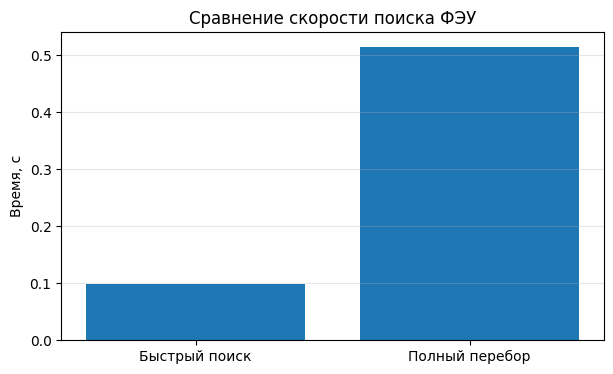

In [27]:
# 7) Сравнение времени
plt.figure(figsize=(7, 4))
plt.bar(['Быстрый поиск', 'Полный перебор'], [t_fast, t_slow])
plt.ylabel('Время, с')
plt.title('Сравнение скорости поиска ФЭУ')
plt.grid(True, axis='y', alpha=0.3)
plt.show()

In [28]:
# 8) Визуализация ФЭУ через k3d
plot = k3d.plot(name='Детектор')
fmt = k3d.points(det.fmt_positions.astype(np.float32), point_size=r, color=0x000100, shader='3d')
source_pt = k3d.points(source.pos.reshape(1, 3).astype(np.float32), point_size=0.5, color=0x0fff00, shader='3d')

plot += fmt
plot += source_pt
plot.display()

Output()